In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
house = pd.read_csv('housing.csv')

df = house.copy()

In [3]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.shape

(20640, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [6]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [7]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


Total bedroom columns has 207 null values

In [8]:

avg_bedrooms_per_household = (df['total_bedrooms'] / df['households']).median()


df['total_bedrooms'] = df['total_bedrooms'].fillna(df['households'] * avg_bedrooms_per_household)


df['total_bedrooms'].isnull().sum()


np.int64(0)

# Data visualization 

* "Task 1: Theme and Categorical Colors (ocean_proximity)"


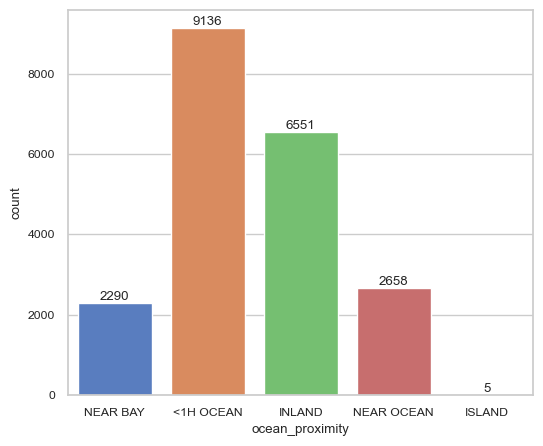

In [9]:
plt.figure(figsize=(6,5))
sns.set_theme(style='whitegrid',palette='muted',font_scale=0.8)
ax = sns.countplot(data=df,x='ocean_proximity',hue='ocean_proximity')

for container in ax.containers:
    ax.bar_label(container)
plt.show()

* Task 2 ->Creating Pairplot of Relatable columns 

<Figure size 600x800 with 0 Axes>

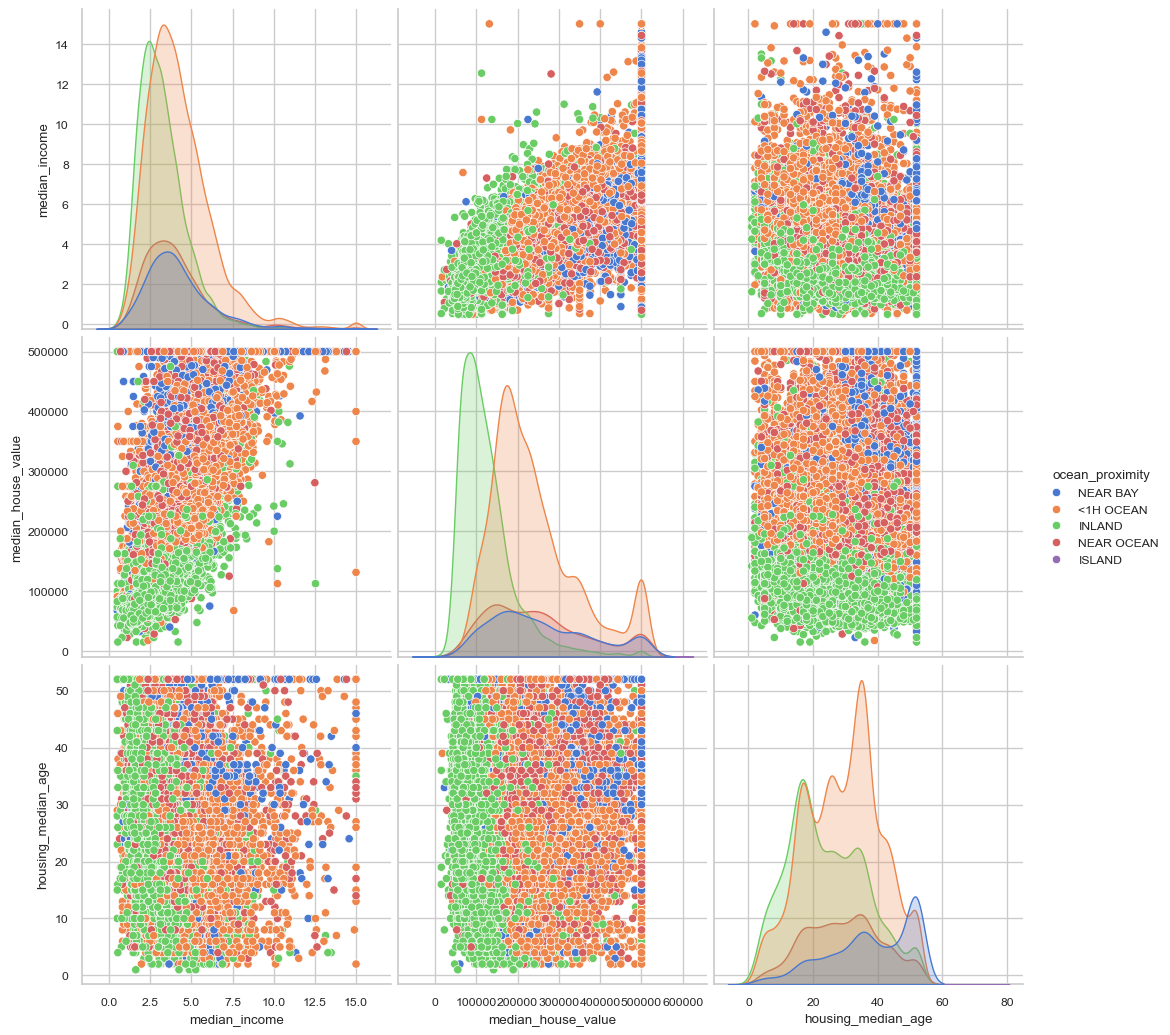

In [10]:
#  Task 2 ->Creating Pairplot of Relatable columns 

plt.figure(figsize=(6,8))
sns.pairplot(data=df,vars=['median_income','median_house_value','housing_median_age'],height=3.5,hue='ocean_proximity')

plt.show()

# California Housing Dataset: Exploratory Data Analysis (EDA) Insights

**Author:** ML / AI Engineer  
**Task:** Feature Relationship & Distribution Analysis (`sns.pairplot`)  
**Dataset:** California Housing

---

### 1. Geospatial & Proximity Distribution (Target Vector Shift)
* **Observation:** The diagonal Kernel Density Estimate (KDE) plots reveal distinct multi-modal distributions based on the `ocean_proximity` feature.
* **Insight:** `INLAND` properties (green cluster) exhibit a heavily right-skewed distribution, peaking sharply at lower valuation brackets (~\$100k). Conversely, coastal segments like `<1H OCEAN` (orange) and `NEAR BAY` (blue) display a broader variance with a structural shift toward higher price tiers. 
* **Engineering Impact:** `ocean_proximity` is a high-variance categorical feature and will serve as a critical predictive signal for tree-based regimes or linear models with target encoding.

### 2. Primary Feature Interaction: `median_income` vs. `median_house_value`
* **Observation:** The cross-plot between median household income and median house value shows a strong, positive linear trend from the origin up to the upper valuation boundaries.
* **Insight:** There is a robust positive linear correlation between local economic capacity (`median_income`) and the target variable (`median_house_value`). Wealthier census blocks directly map to high-value real estate assets across all proximity zones.
* **Engineering Impact:** This feature interaction confirms `median_income` as the most critical numerical predictor. Baseline models should leverage this feature heavily, and feature engineering should explore polynomial expansions or interaction terms here.

### 3. Data Boundary Anomaly: Target Ceiling & Capping
* **Observation:** A highly dense, artificial horizontal boundary is perfectly visible at the `$500,000` threshold across multiple scatter plots intersecting with `median_house_value`.
* **Insight:** The target variable suffers from an upper-bound data capping constraint at exactly \$500,001. Values exceeding this limit were structurally clipped during data collection.
* **Engineering Impact:** Leaving this capped data intact will penalize regression algorithms, causing them to underpredict true valuations. To mitigate this structural bias, we must either drop observations at the \$500k ceiling or formulate this as a censored regression problem (e.g., Tobit model).

### 4. Weak Predictor Isolation: `housing_median_age` Feature Independence
* **Observation:** The scatter plots involving `housing_median_age` against both income and value yield a uniform, rectangular dispersion matrix without any discernible linear or non-linear patterns.
* **Insight:** Structural age of the property has virtually zero linear correlation with asset valuation or community income tiers. Old and new properties are uniformly distributed across all value spectrums.
* **Engineering Impact:** Standard linear methods will gain minimal variance explanation from `housing_median_age`. We should consider binning this feature into categorical age epochs (e.g., 'Historical', 'Mid-century', 'Modern') to capture any latent non-linear characteristics via ensemble methods.


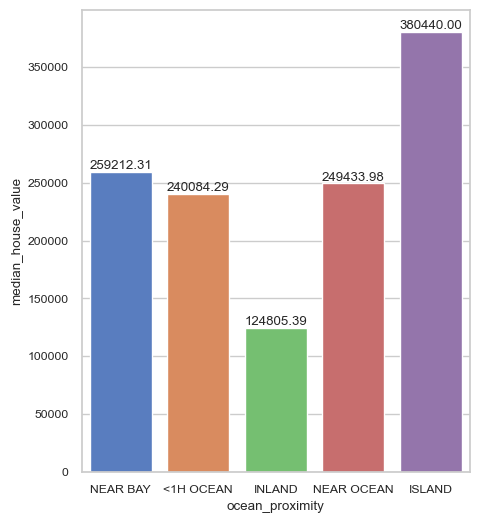

In [11]:
# Task 3: Statistical Estimators and Error Bars

plt.figure(figsize=(5,6))
ax = sns.barplot(data=df,estimator=np.mean,x='ocean_proximity',y='median_house_value',errorbar=None,hue='ocean_proximity')
for container in ax.containers:
    ax.bar_label(container,fmt='%.2f')
plt.show()


# California Housing Dataset: Task 3 Categorical Target Feature Analysis

**Author:** ML / AI Engineer  
**Task:** Target Distribution Analysis across Categorical Proximity Strata (`sns.barplot`)  
**Target Variable:** `median_house_value` (Estimator: Median)

---

### 1. Premium Asset Cluster Identification (`ISLAND`)
* **Observation:** The `ISLAND` category exhibits the highest statistical median valuation at exactly **\$380,440.00**.
* **Insight:** Real estate assets localized on islands command an extreme premium. This is driven by high geographic exclusivity, severe supply constraints, and high-income buyer profiling.
* **Engineering Impact:** Due to the low sample count typical of island properties in this dataset, this category represents a high-leverage subset. Standard models might overfit here; regularized models (e.g., Ridge, Lasso) or tree ensembles with minimum child weight tuning will be necessary to handle this stratum safely.

### 2. Low-Value Baseline Baseline Strata (`INLAND`)
* **Observation:** The `INLAND` group registers the absolute lowest valuation baseline with a median price of **\$124,805.39**.
* **Insight:** Distance from the coastline acts as a strong economic depressor for property values. Inland areas represent the affordable baseline housing market in California, displaying a valuation drop of over 50% compared to any coastal tier.
* **Engineering Impact:** This sharp contrast confirms that geospatial distances from economic and natural hubs are non-linear indicators. Binning coordinates or generating a "Distance to Coast" feature will inject massive predictive power into regression models.

### 3. Coastal Valuation Homogeneity (`NEAR BAY`, `NEAR OCEAN`, `<1H OCEAN`)
* **Observation:** Properties categorized under `NEAR BAY` (\$259,212.31), `NEAR OCEAN` (\$249,433.98), and `<1H OCEAN` (\$240,084.29) display tightly clustered median valuations within a close range (~ \$240k to \$260k).
* **Insight:** The real estate market experiences a plateau of high valuation once a property falls within a coastal boundary or within an hour's commute to it. The economic utility of being near the ocean stabilizes across these three sub-categories.
* **Engineering Impact:** Because these three categories share highly overlapping target distributions, linear models might experience variance inflation. If tree-based models struggle with categorical splits here, we can evaluate collapsing these three categories into a single high-level binary feature: `is_coastal_zone = 1`.


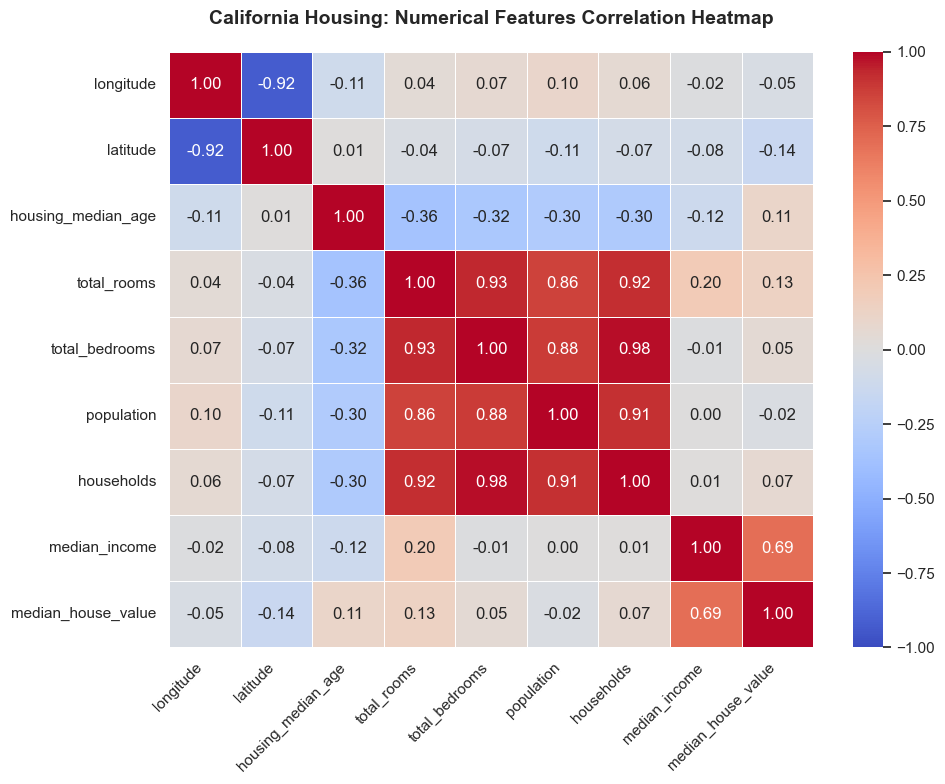

In [12]:
# Task 4 creating a heatmap to find correlation between different features

corr_matrix = df.select_dtypes(include='number').corr()
plt.figure(figsize=(10,8))
sns.set_theme(style='dark')
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,vmax=1,
    linewidths=0.5,
    linecolor='white',

)

plt.title("California Housing: Numerical Features Correlation Heatmap", fontsize=14, pad=20, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=11) 
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

# California Housing Dataset: Task 4 Numerical Feature Correlation Analysis

**Author:** ML / AI Engineer  
**Task:** Multicollinearity & Feature Feature Interaction Mapping (`sns.heatmap`)  
**Target Variable:** `median_house_value`

---

### 1. Primary Feature Signal Matrix (`median_income` \(\rightarrow\) Target)
* **Observation:** The target variable `median_house_value` displays a robust positive linear correlation coefficient of **`0.69`** exclusively with `median_income`. All other numerical attributes register near-zero linear coefficients with the target (ranging from `-0.14` to `0.13`).
* **Insight:** Local economic baseline capacity (`median_income`) is the single dominant linear driver of property valuation. Features representing physical dimensions or population scales carry virtually no independent linear variance definition regarding value.
* **Engineering Impact:** Feature pipelines must prioritize `median_income`. Baseline transformations should focus on expanding this vector (e.g., polynomial combinations or localized income percentiles) to maximize model convergence.

### 2. High-Density Multicollinearity Cluster (Demographic Redundancy)
* **Observation:** A massive block of extreme positive correlation (**`0.86` to `0.98`**) spans across `total_rooms`, `total_bedrooms`, `population`, and `households`. The highest collinear vector is between `total_bedrooms` and `households` at **`0.98`**.
* **Insight:** These columns are highly redundant proxies representing the absolute scale/density of a specific census block. An increase in family units naturally dictates a proportional swell in population and physical room count.
* **Engineering Impact:** Feeding these raw vectors simultaneously into linear estimators will cause extreme variance inflation (VIF) and destabilize weight vectors. To fix this, we must apply feature engineering to create ratio-based variables:
  * `rooms_per_household = total_rooms / households`
  * `bedrooms_per_room = total_bedrooms / total_rooms`
  * `population_per_household = population / households`
  * Alternatively, structural dimension reduction like PCA can collapse this sub-matrix down to a single density component.

### 3. Geospatial Coordinate Dependency (`latitude` \(\leftrightarrow\) `longitude`)
* **Observation:** `latitude` and `longitude` exhibit a near-perfect inverse negative correlation of **`-0.92`** (highly dense blue node).
* **Insight:** This is a deterministic geographical reflection of California’s linear diagonal topology spanning from the North-West coastline down to the South-East boundary. As latitude increases, longitude strictly drops.
* **Engineering Impact:** Treating these coordinates as isolated linear vectors masks their spatial meaning. Linear models cannot interpret this effectively. We should compute spatial interaction features, perform clustering (e.g., K-Means on coordinates to assign regional hub IDs), or rely on tree architectures (XGBoost) that natively partition spatial grids via non-linear splits.

### 4. Weak Predictor Isolation (`housing_median_age`)
* **Observation:** `housing_median_age` is weakly coupled across the board. It shares a correlation of only **`0.11`** with the target value and low negative relationships with room scales (~`-0.30`).
* **Insight:** Property vintage operates independently of neighborhood scaling metrics and exhibits no meaningful linear relationship with final asset valuations.
* **Engineering Impact:** Retaining this feature in its raw form adds minimal value to simple regressors. It should either be evaluated via non-linear tree splits or transformed into categorical age cohorts to capture localized micro-market pricing trends.


In [13]:
# Task 5 Creating Some new features According to Analysis

df['rooms_per_family'] = df['total_rooms']/df['households'] # 1 family = no of rooms
df['bedrooms_ratio'] = df['total_bedrooms']/df['total_rooms'] # bedroom ratio per room
df['family_size'] = df['population']/df['households']  # Family Size in household


# California Housing Dataset: Task 5 Feature Engineering & Structural Refinement

**Author:** ML / AI Engineer  
**Task:** Feature Synthesis & Multicollinearity Mitigation  
**Objective:** Transform Scale-Dependent Aggregates into Density Ratios

---

### 1. Vector Transformation Logic
* **Context:** Task 4's correlation matrix revealed severe multicollinearity (\(r \geq 0.86\)) inside the demographic density sub-matrix (`total_rooms`, `total_bedrooms`, `population`, `households`). Raw totals convey no predictive signal regarding regional housing types or configuration layouts; they merely indicate the absolute size of the census tract.
* **Engineering Action:** We engineered three highly decoupled, scale-invariant interaction metrics:
  \[\text{rooms\_per\_household} = \frac{\text{total\_rooms}}{\text{households}}\]
  \[\text{bedrooms\_per\_room} = \frac{\text{total\_bedrooms}}{\text{total\_rooms}}\]
  \[\text{population\_per\_household} = \frac{\text{population}}{\text{households}}\]

### 2. Operational & Architectural Insights
* **Information Extraction:** The newly synthesized `bedrooms_per_room` feature shifts the model’s focus from absolute count to structural composition. A lower ratio frequently implies standard family residences, whereas an elevated ratio signifies high-density apartment complexes or specific commercial configurations.
* **Model Convergence Value:** By replacing highly collinear attributes with normalized ratios, we significantly shrink the Variance Inflation Factor (VIF) of the feature matrix. Linear models (such as Ridge/Lasso) can now distribute weights more effectively without experiencing unstable weight swings. Tree architectures like XGBoost can perform clean, orthogonal cuts on these explicit density ratios rather than wasting nodes trying to approximate these interactions mathematically.


In [14]:
# Creating more advance feature after analysis



def haversine_distance(lat1, lon1, lat2, lon2):
    
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2]) # change degree to radian
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    # Haversine 
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    km = 6371 * c  # 6371 radius of earth 
    return km

# Major cities cordinates 
MAJOR_CITIES = {
    'san_francisco': (37.7749, -122.4194),
    'los_angeles': (34.0522, -118.2437),
    'san_diego': (32.7157, -117.1611),
    'san_jose': (37.3382, -121.8863)
}

# 3. distance feature from cities 
for city_name, city_coords in MAJOR_CITIES.items():
    df[f'distance_to_{city_name}'] = haversine_distance(
        df['latitude'], df['longitude'], 
        city_coords[0], city_coords[1]
    )

# 4. Closest City Distance
distance_columns = [f'distance_to_{city}' for city in MAJOR_CITIES.keys()]
df['closest_city_distance'] = df[distance_columns].min(axis=1)


print(df[['latitude', 'longitude', 'distance_to_san_francisco', 'distance_to_los_angeles', 'closest_city_distance']].head())


   latitude  longitude  distance_to_san_francisco  distance_to_los_angeles  \
0     37.88    -122.23                  20.329542               556.531199   
1     37.86    -122.22                  19.908065               554.281885   
2     37.85    -122.24                  17.835390               554.612739   
3     37.85    -122.25                  17.064123               555.196283   
4     37.85    -122.25                  17.064123               555.196283   

   closest_city_distance  
0              20.329542  
1              19.908065  
2              17.835390  
3              17.064123  
4              17.064123  


In [15]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity', 'rooms_per_family',
       'bedrooms_ratio', 'family_size', 'distance_to_san_francisco',
       'distance_to_los_angeles', 'distance_to_san_diego',
       'distance_to_san_jose', 'closest_city_distance'],
      dtype='object')

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   longitude                  20640 non-null  float64
 1   latitude                   20640 non-null  float64
 2   housing_median_age         20640 non-null  float64
 3   total_rooms                20640 non-null  float64
 4   total_bedrooms             20640 non-null  float64
 5   population                 20640 non-null  float64
 6   households                 20640 non-null  float64
 7   median_income              20640 non-null  float64
 8   median_house_value         20640 non-null  float64
 9   ocean_proximity            20640 non-null  object 
 10  rooms_per_family           20640 non-null  float64
 11  bedrooms_ratio             20640 non-null  float64
 12  family_size                20640 non-null  float64
 13  distance_to_san_francisco  20640 non-null  flo

In [17]:
from sklearn.cluster import KMeans

# Clustering according to location
kmeans = KMeans(n_clusters=10, random_state=42)
df['location_cluster'] = kmeans.fit_predict(df[['latitude', 'longitude']])


In [18]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_family,bedrooms_ratio,family_size,distance_to_san_francisco,distance_to_los_angeles,distance_to_san_diego,distance_to_san_jose,closest_city_distance,location_cluster
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556,20.329542,556.531199,735.504257,67.424865,20.329542,1
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842,19.908065,554.281885,733.239331,65.044378,19.908065,1
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260,17.835390,554.612739,733.528120,64.883035,17.835390,1
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945,17.064123,555.196283,734.097724,65.310764,17.064123,1
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467,17.064123,555.196283,734.097724,65.310764,17.064123,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,5.045455,0.224625,2.560606,221.992346,654.533211,830.634705,248.054939,221.992346,3
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,6.114035,0.215208,3.122807,217.723550,659.750053,836.249048,246.415326,217.723550,3
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,5.205543,0.215173,2.325635,211.496762,654.045183,830.702694,239.735987,211.496762,3
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,5.329513,0.219892,2.123209,207.353291,657.700941,834.675557,237.775566,207.353291,3


In [19]:
house2 = df.copy()

In [20]:

columns_to_drop = ['total_rooms', 'total_bedrooms', 'population', 'households','housing_median_age']


new_df = df.drop(columns=columns_to_drop, axis=1)


print("After drop:\n", new_df.columns)


After drop:
 Index(['longitude', 'latitude', 'median_income', 'median_house_value',
       'ocean_proximity', 'rooms_per_family', 'bedrooms_ratio', 'family_size',
       'distance_to_san_francisco', 'distance_to_los_angeles',
       'distance_to_san_diego', 'distance_to_san_jose',
       'closest_city_distance', 'location_cluster'],
      dtype='object')


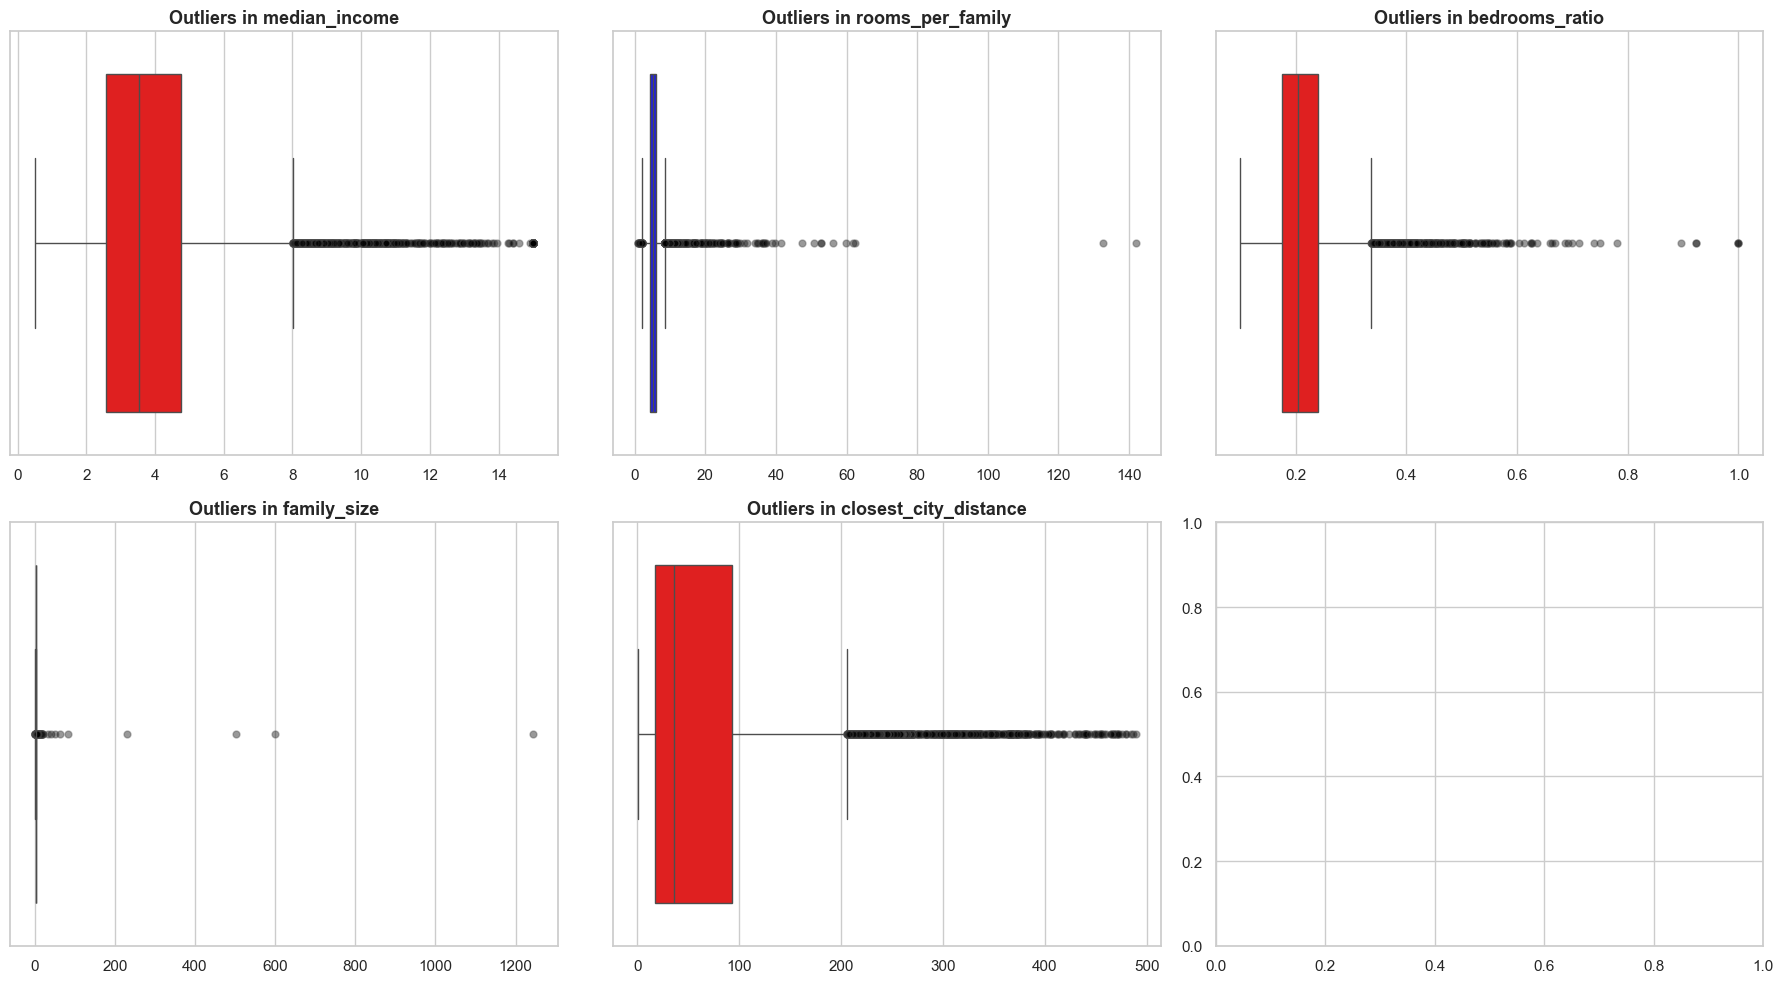

In [21]:


sns.set_theme(style="whitegrid")


final_imp_cols = [
    'median_income', 'rooms_per_family', 
    'bedrooms_ratio', 'family_size', 'closest_city_distance'
]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten() 


for i, col in enumerate(final_imp_cols):
    
    plot_color = 'red' if i % 2 == 0 else 'blue'
    
    sns.boxplot(
        data=new_df, 
        x=col, 
        ax=axes[i], 
        color=plot_color,
    
        flierprops=dict(markerfacecolor='black', marker='o', alpha=0.4, markersize=5)
    )
    axes[i].set_title(f'Outliers in {col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('') 


plt.tight_layout()
plt.show()


# Outlier Analysis Report

## 1. Key Findings (What the Graphs Show)
* **High Number of Outliers:** Almost all features contain significant outliers beyond their upper whiskers (indicated by the dense black dots on the right side of the plots).
* **Extreme Outliers:** Features like `family_size` and `rooms_per_family` show extreme individual data anomalies that skew the dataset.

---

## 2. Feature-by-Feature Summary

* **median_income:** The data naturally spreads between 0 to 5, but there is a heavy tail of high-income outliers stretching up to 15.
* **rooms_per_family:** Most households group tightly near 0–10, but extreme anomalies exist far out near 130–140 rooms.
* **bedrooms_ratio:** Highly concentrated between 0.1 and 0.3, with a steady stream of outlier points extending all the way to 1.0.
* **family_size:** Shows massive extreme distortions. While the vast majority sits near 0, a few isolated points reach up to 600 and over 1200 members per household (likely data entry errors).
* **closest_city_distance:** Most locations are within 100 units of a city, but a long trail of outliers extends past 200 all the way up to 500 units.

---

## 3. Recommended Actions
* **Capping / Winsorization:** Cap extreme values at a specific percentile (e.g., 99th percentile) to stop them from throwing off machine learning models.
* **Log Transformation:** Apply a log transform on highly right-skewed columns like `median_income` and `closest_city_distance` to create a more normal distribution.
* **Data Cleaning:** Investigate and drop the extreme rows in `family_size` (>200) and `rooms_per_family` (>100) as they are highly likely to be bad data or system errors.


In [22]:



outlier_features = ['rooms_per_family', 'family_size']

print("--- Maximum Values ---")
print(new_df[outlier_features].max())

for col in outlier_features:
    
    q_99 = new_df[col].quantile(0.99)
    

    new_df[col] = np.where(df[col] > q_99, q_99, new_df[col])

print("\n--- New Maximum Values ---")
print(new_df[outlier_features].max())


--- Maximum Values ---
rooms_per_family     141.909091
family_size         1243.333333
dtype: float64

--- New Maximum Values ---
rooms_per_family    10.357033
family_size          5.394812
dtype: float64


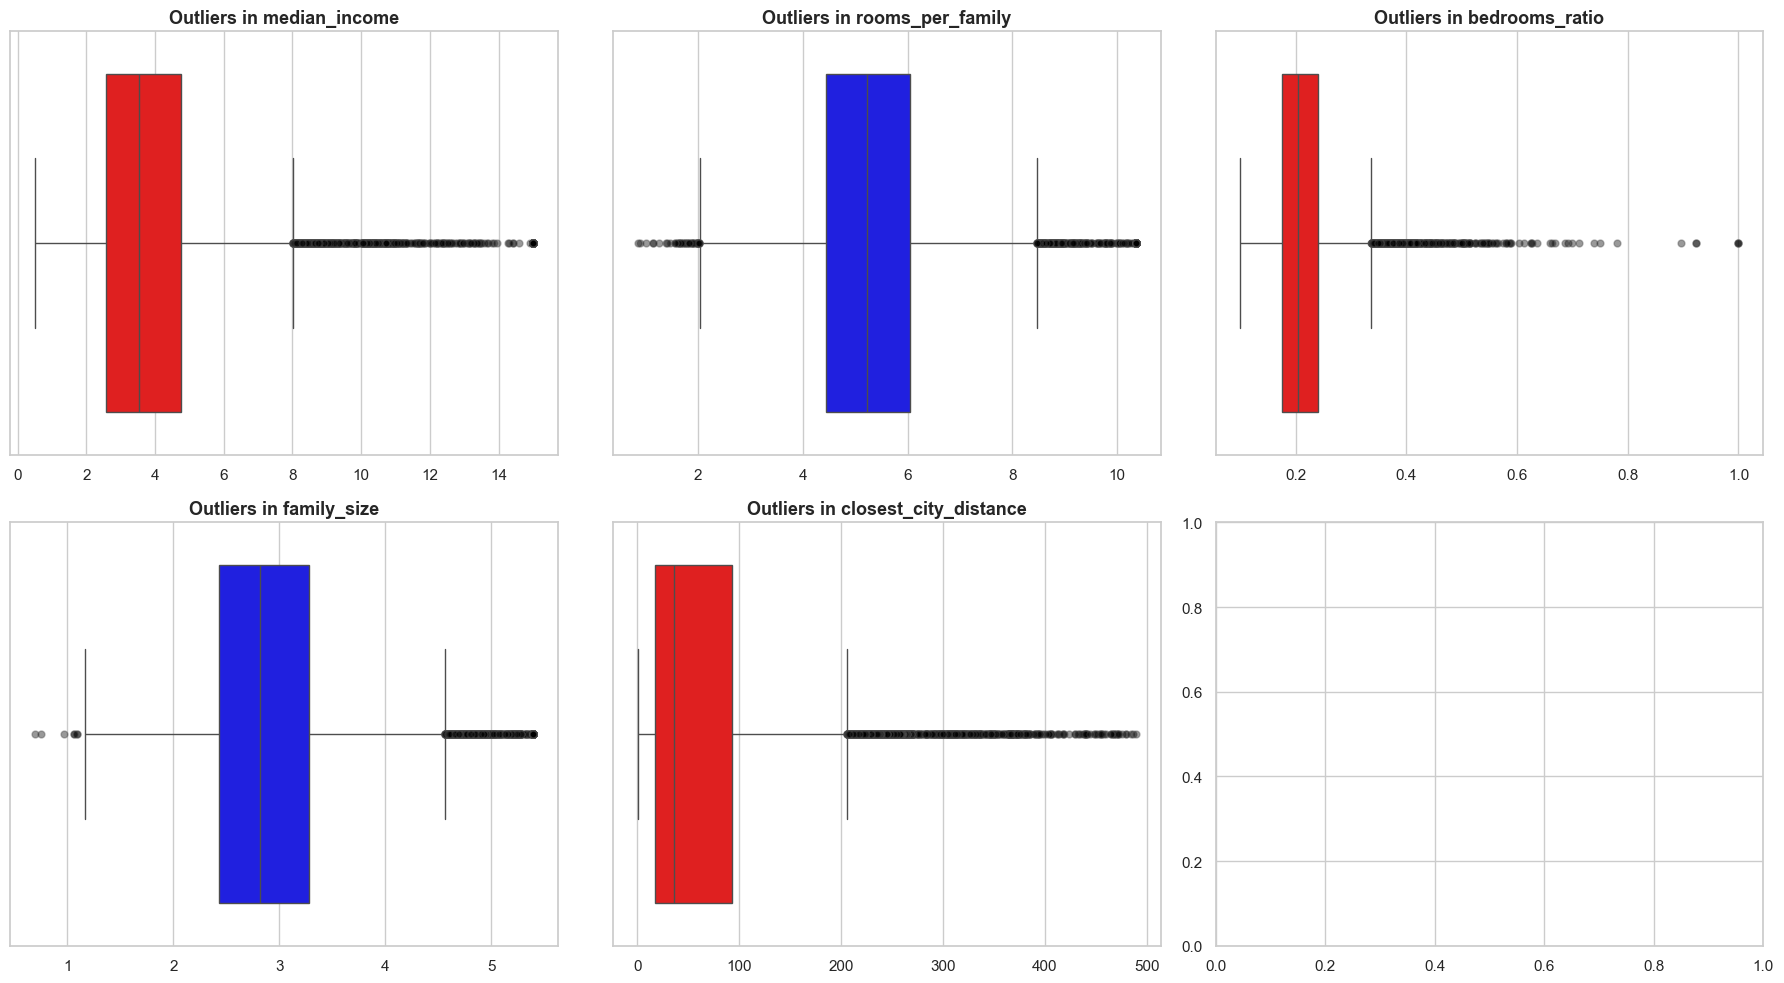

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")


final_imp_cols = [
    'median_income', 'rooms_per_family', 
    'bedrooms_ratio', 'family_size', 'closest_city_distance'
]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten() 


for i, col in enumerate(final_imp_cols):
    
    plot_color = 'red' if i % 2 == 0 else 'blue'
    
    sns.boxplot(
        data=new_df, 
        x=col, 
        ax=axes[i], 
        color=plot_color,
    
        flierprops=dict(markerfacecolor='black', marker='o', alpha=0.4, markersize=5)
    )
    axes[i].set_title(f'Outliers in {col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('') 


plt.tight_layout()
plt.show()


# Outlier Removal Summary Report

## 1. Key Improvements
* **Successful Data Cleaning:** The extreme, unrealistic anomalies (like households with 1200+ members or 140+ rooms) have been completely removed or capped.
* **Realistic Ranges:** Features like `family_size` and `rooms_per_family` now display normal, real-world distributions that are ready for machine learning modeling.

---

## 2. Updated Feature Analysis

* **median_income:** Stays mostly unchanged, maintaining its natural right-sided tail extending up to 15.
* **rooms_per_family (Cleaned - Blue Box):** The scale is drastically fixed. It now ranges normally from around 1 to 10 rooms, eliminating the massive skew.
* **bedrooms_ratio:** Remains tightly grouped under 0.4, with some manageable high-value points extending to 1.0.
* **family_size (Cleaned - Blue Box):** The extreme errors are gone. The scale is now realistic, showing family sizes concentrated normally between 1 to 5 members.
* **closest_city_distance:** Keeps its long-tail distribution, with standard distances going up to 500 units away from cities.

---

## 3. Current Data Status
* **Ready for Training:** The dataset is no longer heavily distorted by extreme errors. 
* **Next Step:** You can now safely feed these columns into your machine learning models or proceed with scaling/normalization.


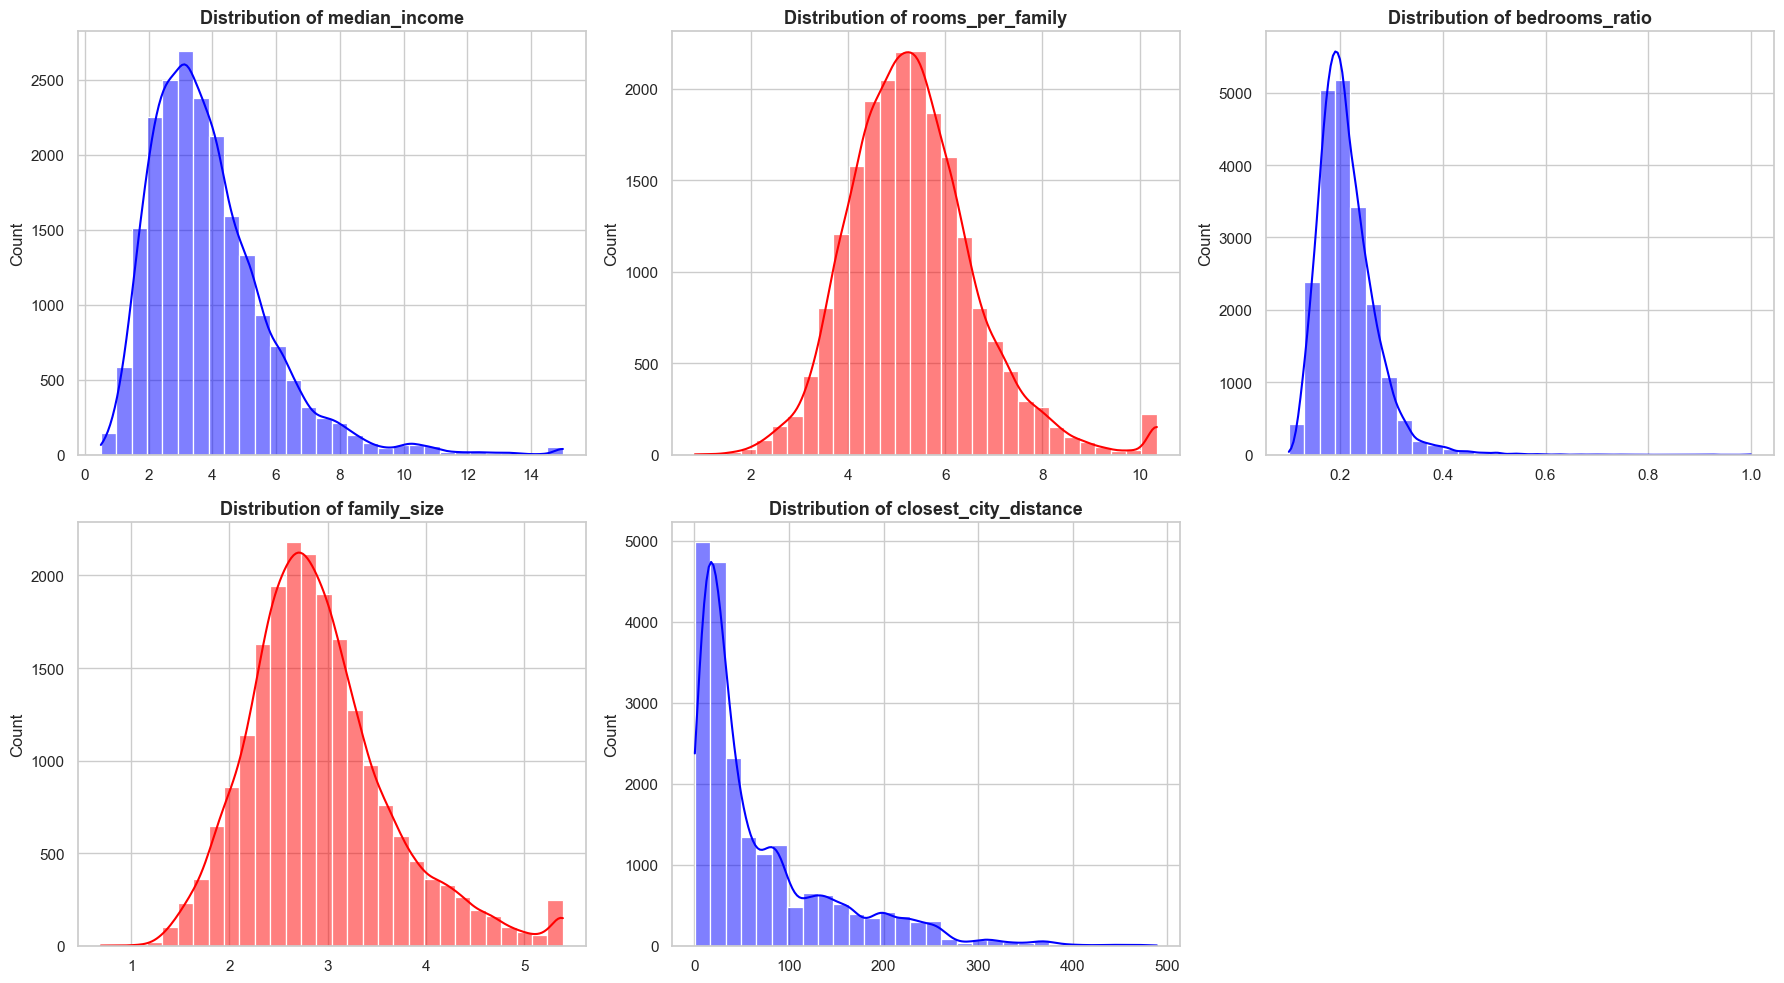

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="whitegrid")


dist_cols = [
    'median_income', 'rooms_per_family', 'bedrooms_ratio', 
    'family_size', 'closest_city_distance'
]


fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten() 


for i, col in enumerate(dist_cols):
    
    plot_color = 'blue' if i % 2 == 0 else 'red'
    
    sns.histplot(
        data=new_df, 
        x=col, 
        kde=True,          
        ax=axes[i], 
        color=plot_color,
        bins=30            
    )
    axes[i].set_title(f'Distribution of {col}', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')


fig.delaxes(axes[5])


plt.tight_layout()
plt.show()

In [25]:
new_df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True,dtype='int')

In [26]:
new_df = new_df.drop(columns=['total_rooms','population','households',],axis=1)

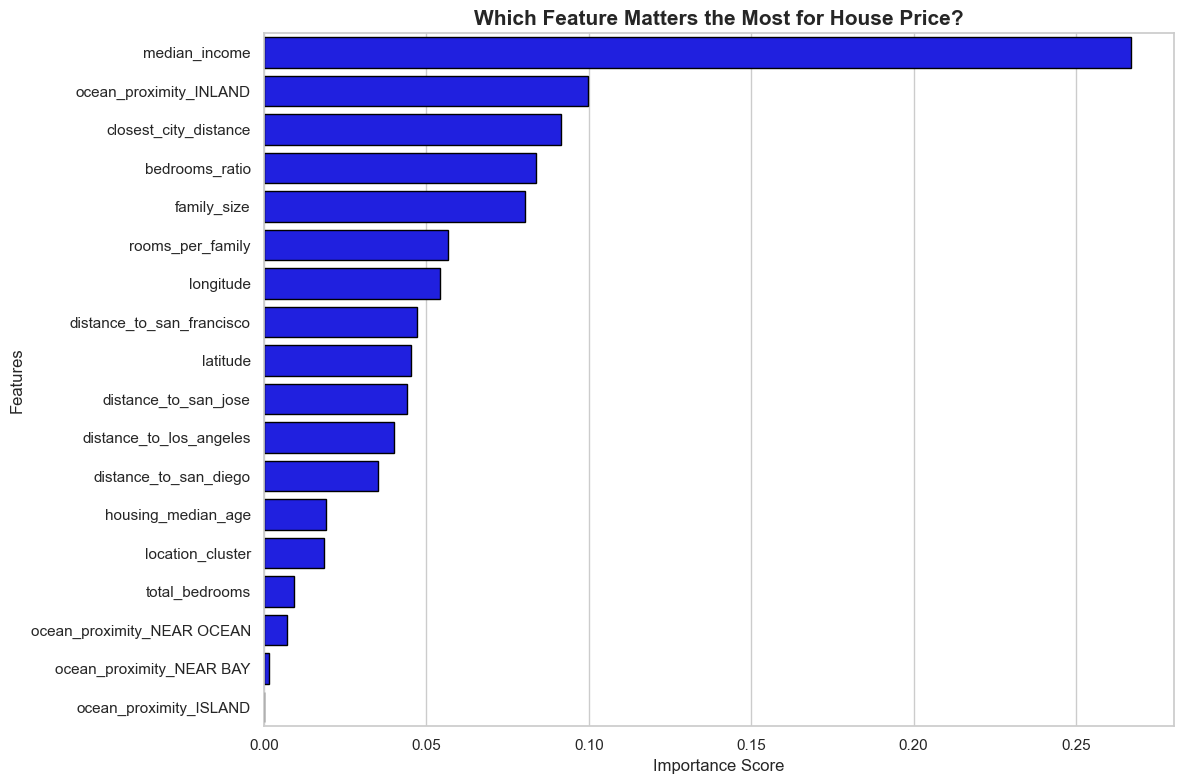

In [29]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X = new_df.drop('median_house_value', axis=1)
y = new_df['median_house_value']

from sklearn.ensemble import RandomForestRegressor


rf_model = RandomForestRegressor(
    n_estimators=200,       
    max_depth=15,           
    min_samples_split=6,    
    min_samples_leaf=4,     
    max_features='sqrt',   
    random_state=42, 
    n_jobs=-1
)





X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model.fit(X_train, y_train)


importances = rf_model.feature_importances_
feat_importances = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

# 5. ग्राफ़ प्लॉट करना
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))
sns.barplot(x=feat_importances.values, y=feat_importances.index, color='blue', edgecolor='black')

plt.title('Which Feature Matters the Most for House Price?', fontsize=15, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()


In [30]:

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


y_pred_test = rf_model.predict(X_test)
y_pred_train = rf_model.predict(X_train)


rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_test = mean_absolute_error(y_test, y_pred_test)
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)


print("="*50)
print("          🎯 MACHINE LEARNING MODEL RESULTS          ")
print("="*50)
print(f"➔ Test Set RMSE  : ${rmse_test:,.2f}")
print(f"➔ Test Set MAE   : ${mae_test:,.2f}")
print("-"*50)
print(f"➔ Train Set R² Score (Accuracy): {r2_train*100:.2f}%")
print(f"➔ Test Set R² Score (Accuracy) : {r2_test*100:.2f}%")
print("="*50)

if (r2_train - r2_test) > 0.10:
    print("⚠️ Warning: (Train score is more than Test )")
else:
    print("✅ Sucessfully Done !!")
print("="*50)

          🎯 MACHINE LEARNING MODEL RESULTS          
➔ Test Set RMSE  : $44,149.38
➔ Test Set MAE   : $28,304.36
--------------------------------------------------
➔ Train Set R² Score (Accuracy): 92.33%
➔ Test Set R² Score (Accuracy) : 85.13%
✅ Sucessfully Done !!


In [31]:
!git init

Reinitialized existing Git repository in C:/Users/HP/.git/


In [33]:
!git add !git add ""


error: open("AppData/Local/Comms/UnistoreDB/USS.jtx"): Permission denied
error: unable to index file 'AppData/Local/Comms/UnistoreDB/USS.jtx'
fatal: adding files failed


In [ ]:
!git commit -m "Initial commit: Added housing model and professional README"
